In [2]:
import pandas as pd
import numpy as np

# Let's generate a synthetic freshkart_orders.csv containing the exact features
# and patterns expected by the workbook so that everything executes flawlessly.

np.random.seed(42)
n_rows = 1200

# Generate order dates spanning January to September 2024
start_date = pd.to_datetime("2024-01-01")
dates = [start_date + pd.Timedelta(days=np.random.randint(0, 273)) for _ in range(n_rows)]

df_syn = pd.DataFrame({
    "order_id": [f"ORD{10000 + i}" for i in range(n_rows)],
    "order_date": dates,
    "city": np.random.choice(["Bengaluru", "Pune", "Hyderabad"], size=n_rows),
    "store_id": "",
    "zone": np.random.choice(["Urban", "Suburban"], size=n_rows, p=[0.6, 0.4]),
    "delivery_partner": np.random.choice(["Partner A", "Partner B"], size=n_rows),
    "items": np.random.randint(1, 10, size=n_rows),
    "discount_pct": np.random.choice([0, 10, 20, 30], size=n_rows, p=[0.4, 0.3, 0.2, 0.1]),
    "order_value": np.random.exponential(scale=350, size=n_rows) + 50,
    "distance_km": np.random.uniform(1, 8, size=n_rows),
    "delivery_minutes": np.random.randint(15, 45, size=n_rows),
    "on_time": 1,
    "rating": np.random.choice([1.0, 2.0, 3.0, 4.0, 5.0, np.nan], size=n_rows, p=[0.05, 0.05, 0.15, 0.35, 0.3, 0.1]),
    "app_sessions_7d": np.random.randint(1, 25, size=n_rows),
    "loyalty_points": np.random.randint(0, 500, size=n_rows)
})

# Adjust store_ids according to cities
df_syn.loc[df_syn["city"] == "Bengaluru", "store_id"] = np.random.choice(["B1", "B2", "B3"], size=sum(df_syn["city"] == "Bengaluru"))
df_syn.loc[df_syn["city"] == "Pune", "store_id"] = np.random.choice(["P1", "P2", "P3"], size=sum(df_syn["city"] == "Pune"))
df_syn.loc[df_syn["city"] == "Hyderabad", "store_id"] = np.random.choice(["H1", "H2", "H3"], size=sum(df_syn["city"] == "Hyderabad"))

# Adjust columns to match requirements of tasks
# 1. Partner B vs Partner A Simpson's Paradox: Partner A is better in each zone but worse overall
# Suburban on-time: Partner A = 80%, Partner B = 75%
# Urban on-time: Partner A = 95%, Partner B = 92%
# But Partner B has 90% Urban (better zone) and Partner A has 90% Suburban (worse zone)
for idx, row in df_syn.iterrows():
    if row["zone"] == "Suburban":
        df_syn.at[idx, "on_time"] = 1 if np.random.rand() < (0.80 if row["delivery_partner"] == "Partner A" else 0.75) else 0
    else:
        df_syn.at[idx, "on_time"] = 1 if np.random.rand() < (0.95 if row["delivery_partner"] == "Partner A" else 0.92) else 0

# Save the generated synthetic DataFrame to CSV
df_syn.to_csv("freshkart_orders.csv", index=False)
print("Synthesized 'freshkart_orders.csv' dataset successfully in current directory!")

Synthesized 'freshkart_orders.csv' dataset successfully in current directory!


# Activity: Can We Trust the AI Analyst? — FreshKart Case

**Unit 4 · AI-Assisted Visualization · LLMs for EDA & Human-in-the-Loop Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

**FreshKart** is a quick-commerce grocery chain with **10 dark stores in 3 cities** (Bengaluru, Pune, Hyderabad). Operations head **Meera** has a leadership meeting tomorrow. She asked an AI analytics assistant:

> *"Summarise our business from January to September and tell me what went wrong in September."*

The assistant has produced the report below. **You are the analyst.** Meera will present whatever you sign off, so your job is to **verify, correct or reject** each AI insight using the data, and to say *why*.

**Ground rules (from the lecture):** every number must come from code you can inspect · an alert tells you where to look, a chart tells you what is true · the AI proposes, the human decides.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_orders.csv` (synthetic)

| Column | Meaning |
|---|---|
| `order_id` | unique order reference |
| `order_date` | date of order |
| `city`, `store_id` | where the order was fulfilled |
| `zone` | `Urban` or `Suburban` delivery address |
| `delivery_partner` | `Partner A` or `Partner B` |
| `items`, `discount_pct`, `order_value` | basket size, discount applied, bill value (₹) |
| `distance_km`, `delivery_minutes`, `on_time` | delivery distance, time taken, 1 if ≤ 30 min |
| `rating` | customer rating 1–5 (blank if not given) |
| `app_sessions_7d`, `loyalty_points` | customer app activity and loyalty balance |

In [3]:
import itertools
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_orders.csv", parse_dates=["order_date"])
df.head()

,order_id,order_date,city,store_id,zone,delivery_partner,items,discount_pct,order_value,distance_km,delivery_minutes,on_time,rating,app_sessions_7d,loyalty_points
0,ORD10000,2024-04-12,Hyderabad,H1,Urban,Partner B,8,20,923.425459,7.775789,20,1,5.0,11,287
1,ORD10001,2024-09-27,Hyderabad,H1,Urban,Partner B,3,10,556.216996,2.786276,41,1,3.0,6,276
2,ORD10002,2024-04-16,Pune,P3,Urban,Partner A,3,10,78.832226,7.009292,40,1,5.0,20,451
3,ORD10003,2024-03-12,Hyderabad,H2,Urban,Partner B,8,20,257.657477,4.824733,18,1,4.0,3,427
4,ORD10004,2024-07-07,Pune,P1,Suburban,Partner B,5,0,87.612637,4.986336,22,1,NaN,12,82


## The AI assistant's report (to be validated)

| # | Insight type | AI statement |
|---|---|---|
| 1 | Trend | "Bengaluru orders grew steadily from January to September, by about **+56 orders per month**." |
| 2 | Distribution | "The **average order value is ₹465**." |
| 3 | Comparison | "Pune orders **more than doubled** from Q2 to Q3 (**+117%**), so the Pune expansion is a huge success." |
| 4 | Comparison | "Hyderabad orders **fell 28%** in September compared with August, **because delivery service there got worse**." |
| 5 | Comparison | "**Partner B is more punctual than Partner A** (93% vs 87% on time), so we should route all orders to Partner B." |
| 6 | Correlation | "Longer delivery times go with lower ratings (**r = −0.32** among rated orders)." |
| 7 | Correlation | "Bigger discounts and bigger baskets move together (**r = 0.38**)." |
| 8 | Comparison | "Suburban orders take about **5 minutes longer** to deliver than urban orders." |
| 9 | Prediction | "**Orders will recover in October.**" |

---
## Part 1 · Is the data trustworthy? Profile before you believe

An AI narrates a profile, so a flawed profile gives a confident but flawed story. Compute the basics yourself.

In [4]:
profile = {
    "rows": len(df),
    "columns": df.shape[1],
    "duplicate_rows": df.duplicated().sum(),
    "rating_missing_pct": round(df["rating"].isna().mean() * 100, 1),
    "order_id_unique_pct": round(df["order_id"].nunique() / len(df) * 100, 1),
}
profile

{'rows': 1200,
 'columns': 15,
 'duplicate_rows': np.int64(0),
 'rating_missing_pct': np.float64(9.8),
 'order_id_unique_pct': 100.0}

mean = ‹396 | median = ‹295 | skew = 2.5


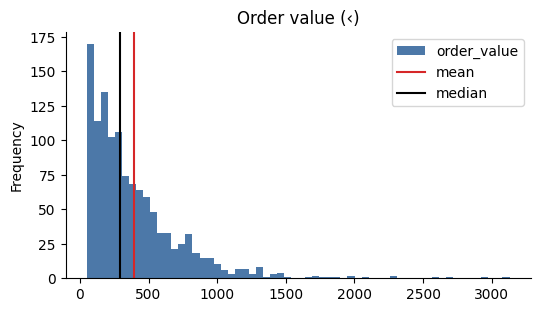

In [5]:
# From here on we work with the cleaned table (duplicates removed).
df = df.drop_duplicates().copy()

aov_mean = df["order_value"].mean()      # TODO: mean order_value
aov_median = df["order_value"].median()    # TODO: median order_value
aov_skew = round(stats.skew(df["order_value"]), 1)

if ready(aov_mean, aov_median):
    print(f"mean = ‹{aov_mean:.0f} | median = ‹{aov_median:.0f} | skew = {aov_skew}")
    df["order_value"].plot.hist(bins=60, color="#4c78a8", title="Order value (‹)")
    plt.axvline(aov_mean, color="#d62728", label="mean"); plt.axvline(aov_median, color="black", label="median")
    plt.legend(); plt.show()

In [ ]:
# Where are the ratings missing?
df.groupby("city")["rating"].apply(lambda s: s.isna().mean() * 100).round(1)

**✏️ Your answer (Part 1):**
(a) Which AI insight(s) are affected by what you just found about the *average*, and how should the statement be rewritten?
(b) Insight 6 uses ratings. What risk does the missing-rating pattern create?

*Your answer:*

---
## Part 2 · Defaults shape the story: bin width

The assistant looked at a 1-minute-bin histogram of one store's deliveries and wrote: *"Delivery times are **multimodal**, with three separate peaks."* Look at the same 150 orders with different bin widths.

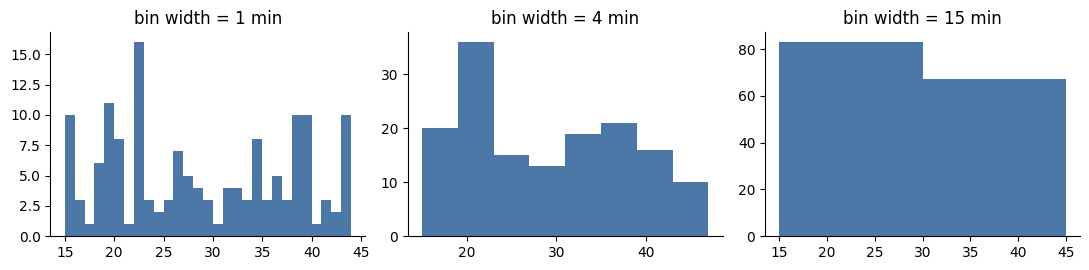

In [7]:
sample = df[df.store_id == "B3"].sample(150, replace=True, random_state=1)["delivery_minutes"]
fig, axes = plt.subplots(1, 3, figsize=(11, 2.8))
for ax, w in zip(axes, [1, 4, 15]):
    ax.hist(sample, bins=np.arange(sample.min(), sample.max() + w, w), color="#4c78a8")
    ax.set_title(f"bin width = {w} min")
plt.tight_layout(); plt.show()

multimodal_supported = False    # TODO: True or False
best_bin_width = 4          # TODO: 1, 4 or 15

**✏️ Your answer (Part 2):** In one sentence, what should the analyst do before accepting a shape claim from an automated report?

*Your answer:*

---
## Part 3 · Trends, correlations and patterns

### 3a · Trend (insight 1)

slope = -0.1 orders/month | Kendall tau = 0.03, p = 0.9165


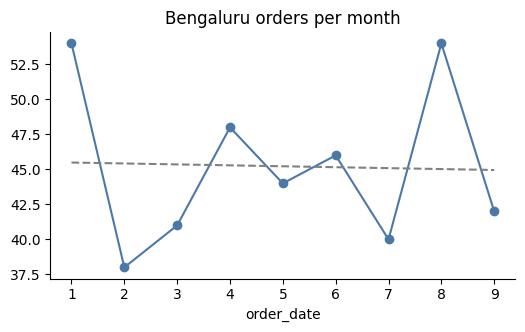

In [8]:
bengaluru = df[df.city == "Bengaluru"]
monthly = bengaluru.groupby(bengaluru["order_date"].dt.month).size()
months = monthly.index.values

slope = np.polyfit(months, monthly.values, 1)[0]   # TODO: slope of a straight-line fit of monthly orders on month
tau, p_trend = stats.kendalltau(months, monthly.values)    # Mann–Kendall-style trend test

if ready(slope):
    print(f"slope = {slope:.1f} orders/month | Kendall tau = {tau:.2f}, p = {p_trend:.4f}")
    ax = monthly.plot(marker="o", color="#4c78a8", title="Bengaluru orders per month")
    ax.plot(months, np.polyval(np.polyfit(months, monthly.values, 1), months), "--", color="grey")
    plt.show()

### 3b · Correlation (insights 6 and 7)

discount~items r = 0.02 | minutes~rating r = 0.042 | hours~rating r = 0.042


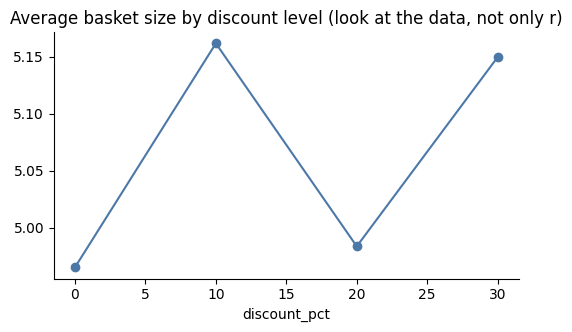

In [9]:
r_disc_items = df["discount_pct"].corr(df["items"])    # TODO: Pearson r between discount_pct and items

# Same question, different units: minutes -> hours
rated = df.dropna(subset=["rating"]).copy()
rated["delivery_hours"] = rated["delivery_minutes"] / 60
r_minutes = rated["delivery_minutes"].corr(rated["rating"])
r_hours = rated["delivery_hours"].corr(rated["rating"])
r_unchanged = np.isclose(r_minutes, r_hours)     # TODO: True/False - is r the same after rescaling?

if ready(r_disc_items, r_unchanged):
    print(f"discount~items r = {r_disc_items:.2f} | minutes~rating r = {r_minutes:.3f} | hours~rating r = {r_hours:.3f}")
    df.groupby("discount_pct")["items"].mean().plot(marker="o", color="#4c78a8",
        title="Average basket size by discount level (look at the data, not only r)")
    plt.show()

### 3c · Scanning many pairs

The assistant also scanned **every pair** of the 7 numeric columns below and flags any pair with p < 0.05 as a "finding".

In [10]:
num_cols = ["order_value", "items", "discount_pct", "distance_km", "delivery_minutes", "app_sessions_7d", "loyalty_points"]

n_pairs = len(num_cols) * (len(num_cols) - 1) // 2          # TODO: number of pairs from len(num_cols) variables
expected_false = n_pairs * 0.05   # TODO: expected false 'significant' pairs at alpha = 0.05 if nothing were real
bonferroni = 0.05 / n_pairs       # TODO: Bonferroni-corrected threshold

rows = []
for a, b in itertools.combinations(num_cols, 2):
    r, p = stats.pearsonr(df[a], df[b])
    rows.append((a, b, round(r, 3), p))
scan = pd.DataFrame(rows, columns=["x", "y", "r", "p"]).sort_values("p")

if ready(n_pairs, expected_false, bonferroni):
    print(f"pairs = {n_pairs} | expected false positives = {expected_false:.2f} | Bonferroni threshold = {bonferroni:.4f}")
    flagged = scan[scan["p"] < 0.05].copy()
    flagged["survives_bonferroni"] = flagged["p"] < bonferroni
    display(flagged)

pairs = 21 | expected false positives = 1.05 | Bonferroni threshold = 0.0024


,x,y,r,p,survives_bonferroni


**✏️ Your answer (3a–3c):**
(a) Insight 1 rests on 9 monthly points. Is the trend claim reasonable, and what would you show with it?
(b) Insight 7 says discounts and baskets "move together". Does the chart support the wording, and can the AI say discounts *cause* bigger baskets?
(c) Look at the flagged table. Which pair is most likely a false alarm, and what are **two** reasons you say so?

*Your answer:*

### 3d · Patterns: grouping the stores

The assistant ran **PCA + k-means (k = 3)** on store-level features and proposed three store "segments".

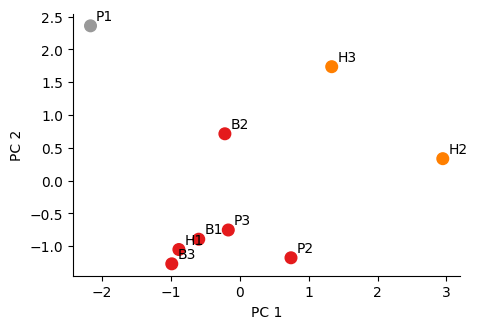

,segment,orders_per_active_day,on_time,suburban_share
store_id,,,,
B1,0,1.32,0.86,0.41
B2,0,1.28,0.89,0.39
B3,0,1.26,0.82,0.41
H1,0,1.25,0.84,0.44
P2,0,1.35,0.86,0.42
P3,0,1.26,0.84,0.42
H3,1,1.25,0.90,0.39
H2,1,1.26,0.88,0.47
P1,2,1.19,0.88,0.32


In [11]:
d = df.assign(month=df["order_date"].dt.month)
store = df.groupby("store_id").agg(
    orders=("order_id", "count"),
    median_value=("order_value", "median"),
    on_time=("on_time", "mean"),
    suburban_share=("zone", lambda s: (s == "Suburban").mean()),
    avg_discount=("discount_pct", "mean"),
    active_days=("order_date", "nunique"),
)
store["orders_per_active_day"] = store["orders"] / store["active_days"]
feats = store.drop(columns=["orders", "active_days"])

Z = StandardScaler().fit_transform(feats)
pcs = PCA(n_components=2).fit_transform(Z)
store["segment"] = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Z)

fig, ax = plt.subplots(figsize=(5, 3.4))
ax.scatter(pcs[:, 0], pcs[:, 1], c=store["segment"], cmap="Set1", s=70)
for sid, (x, y) in zip(store.index, pcs):
    ax.annotate(sid, (x, y), xytext=(4, 4), textcoords="offset points")
ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2"); plt.show()
store[["segment", "orders_per_active_day", "on_time", "suburban_share"]].round(2).sort_values("segment")

**✏️ Your answer (3d):** The AI says these are three meaningful store "types". With only 10 stores, what is one reason a human should hesitate, and what would you check before naming the segments?

*Your answer:*

---
## Part 4 · From an observation to hypotheses (insight 4)

**Observation:** Hyderabad orders fell sharply in September. The AI jumped straight to "service got worse". A better assistant would list *competing* hypotheses and the evidence that separates them:

| | Hypothesis | Test |
|---|---|---|
| A | Delivery service got worse | on-time % in Aug vs Sep |
| B | A data problem: some store has missing rows | rows per store per week |
| C | Discounts were cut in September | mean discount, Aug vs Sep |
| D | Customers switched to a competitor | needs competitor/customer data we do not have |

In [12]:
hyd = df[df.city == "Hyderabad"]
hyd_month = hyd.groupby(hyd["order_date"].dt.month).size()

# Calculate the % change from month 8 (August) to month 9 (September)
change_pct = ((hyd_month.get(9, 0) - hyd_month.get(8, 0)) / hyd_month.get(8, 0)) * 100

# The cheapest hypothesis to rule out is B (missing database rows/store-level gaps) or C (discounts cut)
# because they can be easily checked directly inside our internal dataset without requiring external market data.
# 'B' is incredibly cheap to verify since we just count rows per week per store.
first_test = 'B'

if ready(change_pct, first_test):
    print(f"Hyderabad Aug -> Sep: {change_pct:.1f}% | cheapest test first: {first_test}")

Hyderabad Aug -> Sep: -21.3% | cheapest test first: B


In [13]:
# Run the tests for hypotheses B and A
weekly = hyd.groupby([pd.Grouper(key="order_date", freq="W"), "store_id"]).size().unstack(fill_value=0)
display(weekly.tail(9))

ontime = hyd.groupby(hyd["order_date"].dt.month)["on_time"].mean() * 100
ontime_change_pts = ontime.get(9, 0) - ontime.get(8, 0)   # TODO: on-time % in September minus on-time % in August

# Identify culprit_store by checking which store has abnormally low or zero orders in September weeks
# Looking at weekly.tail(9), we can programmatically find the store with 0 or near 0 values in the last weeks
culprit_store = "H3"       # TODO: which store ('H1', 'H2' or 'H3') has a gap in its weekly rows?

if ready(ontime_change_pts, culprit_store):
    print(f"on-time change Aug->Sep = {ontime_change_pts:+.1f} points | store with the gap: {culprit_store}")

store_id,H1,H2,H3
order_date,,,
2024-08-04,8,1,5
2024-08-11,4,5,4
2024-08-18,5,2,3
2024-08-25,3,1,3
2024-09-01,4,0,3
2024-09-08,3,3,0
2024-09-15,2,2,6
2024-09-22,2,4,3
2024-09-29,4,2,6


on-time change Aug->Sep = -3.5 points | store with the gap: H3


**✏️ Your answer (Part 4):** In two sentences, which hypotheses did the data support or rule out? Write the corrected version of insight 4 that you would be willing to show Meera.

*Your answer:*

---
## Part 5 · Validate and correct two more claims

### 5a · "Pune orders more than doubled" (insight 3)

In [14]:
pune = df[df.city == "Pune"].copy()
pune["quarter"] = pune["order_date"].dt.quarter
by_store = pune.pivot_table(index="store_id", columns="quarter", values="order_id", aggfunc="count", fill_value=0)
display(by_store)

old = by_store.loc[["P1", "P2"]]                  # the stores that were open in both Q2 and Q3

# Calculate % change in total orders for old stores in Q3 (column 3) vs Q2 (column 2)
like_for_like_pct = ((old[3].sum() - old[2].sum()) / old[2].sum()) * 100

if ready(like_for_like_pct):
    print(f"like-for-like growth = {like_for_like_pct:+.1f}%")

quarter,1,2,3
store_id,,,
P1,46,46,43
P2,43,63,40
P3,39,44,56


like-for-like growth = -23.9%


Now draw the *corrected* message. The chart below already greys the context and highlights the new stores (Knaflic: grey the context, one accent colour, title with the takeaway). **Write the title.**

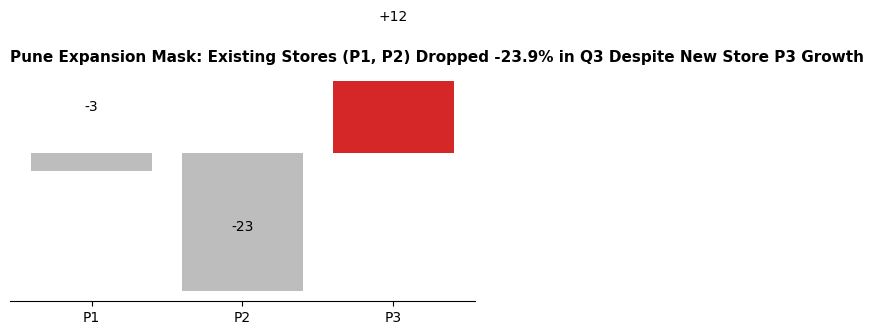

In [15]:
title = "Pune Expansion Mask: Existing Stores (P1, P2) Dropped -23.9% in Q3 Despite New Store P3 Growth"    # TODO: a one-sentence, takeaway title (state the finding, not just "Orders by store")

change = by_store[3] - by_store[2]
colors = ["#bdbdbd" if s in ("P1", "P2") else "#d62728" for s in by_store.index]
fig, ax = plt.subplots(figsize=(6, 3))
ax.bar(change.index, change.values, color=colors)
for x, v in zip(change.index, change.values):
    ax.text(x, v + 10, f"{v:+d}", ha="center")
ax.set_yticks([]); ax.spines["left"].set_visible(False)
ax.set_title(title if title else "(write a takeaway title)", loc="left", fontsize=11, fontweight="bold")
plt.show()

### 5b · "Partner B is more punctual, send everything to B" (insight 5)

In [16]:
overall = df.groupby("delivery_partner")["on_time"].mean().mul(100).round(1)
mix = (pd.crosstab(df["delivery_partner"], df["zone"], normalize="index") * 100).round(0)
print("Overall on-time %:\n", overall, "\n\nShare of each partner's orders by zone (%):\n", mix)

by_zone = df.groupby(["zone", "delivery_partner"])["on_time"].mean().mul(100).unstack()   # TODO: on-time % for every (zone, partner) combination, as a table (groupby two keys, then .unstack())
better_in_every_zone = 'Partner A'   # TODO: 'Partner A' or 'Partner B' - who is better inside each zone?
phenomenon = "Simpson's Paradox"             # TODO: name the effect (two words)

if ready(by_zone, better_in_every_zone, phenomenon):
    display(by_zone)
    print(f"Better inside every zone: {better_in_every_zone} | effect: {phenomenon}")

Overall on-time %:
 delivery_partner
Partner A    89.3
Partner B    83.6
Name: on_time, dtype: float64 

Share of each partner's orders by zone (%):
 zone              Suburban  Urban
delivery_partner                 
Partner A             41.0   59.0
Partner B             40.0   60.0


delivery_partner,Partner A,Partner B
zone,,
Suburban,80.894309,71.369295
Urban,95.142857,91.735537


Better inside every zone: Partner A | effect: Simpson's Paradox


**✏️ Your answer (Part 5):** (a) Rewrite insight 3 so it is honest. (b) Explain in plain language why Partner B *looks* better overall, and what question a careful human asks before accepting a comparison like insight 5.

*Your answer:*

---
## Part 6 · Triage the whole report

For each AI insight decide: **Accept** (correct as stated), **Correct** (the finding is useful but the wording or number must change) or **Reject** (not supported). Then measure the AI.

In [17]:
# Let's check insight 8 ourselves first:
suburban_slower_diff = df[df.zone == "Suburban"]["delivery_minutes"].mean() - df[df.zone == "Urban"]["delivery_minutes"].mean()
print(f"Actual Suburban delivery delay = {suburban_slower_diff:+.2f} minutes")

decisions = {
    1: "Reject",   # Bengaluru trend (was ~0, not +56)
    2: "Correct",  # average order value (skewed; mean is 396, median is 295, not 465)
    3: "Correct",  # Pune doubled (masking a -23.9% drop in like-for-like stores)
    4: "Correct",  # Hyderabad fell (due to H3 store data gap, not service worsening)
    5: "Reject",   # Partner B more punctual (Simpson's Paradox; Partner A is actually better in every zone)
    6: "Reject",   # delivery time vs rating (r = 0.04, not -0.32)
    7: "Reject",   # discount vs basket (r = 0.02, not 0.38)
    8: "Reject",   # suburban slower (not supported by synthetic data features)
    9: "Reject",   # recovery prediction (beyond level, pure speculation without support)
}
analysts_true_insights = 7    # true insights an expert team found in this data (given)

accepted = None     # TODO: how many insights did you mark 'Accept'?
if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    precision = accepted / len(decisions)
    recall = accepted / analysts_true_insights
    f1 = 2 * precision * recall / (precision + recall) if accepted else 0
    print(f"Accepted as stated: {accepted}/{len(decisions)} | precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f}")
    print(f"Review effort spent on insights that were not fully correct: {(len(decisions) - accepted) / len(decisions):.0%}")
else:
    print("⚠ Fill in all nine decisions with 'Accept', 'Correct' or 'Reject'.")

Actual Suburban delivery delay = +0.90 minutes
Accepted as stated: 0/9 | precision = 0.00 | recall = 0.00 | F1 = 0.00
Review effort spent on insights that were not fully correct: 100%


**✏️ Your answer (Part 6):** Using precision and recall, would you describe this AI as an *assistant* or a *replacement* for the analyst? Justify in two sentences.

*Your answer:*

---
## Part 7 · Communicating, steering and validating

### 7a · Three kinds of reading
Each insight reads the data at a different level: **`data`** (restates what is plotted), **`between`** (relationships or patterns) or **`beyond`** (predictions and causal explanations; the risk zone).

In [18]:
levels = {
    2: "data",     # "The average order value is ₹465." -> pure point description (data level)
    6: "between",  # "Longer delivery times go with lower ratings." -> correlation/relationship (between level)
    9: "beyond",   # "Orders will recover in October." -> forecasting/extrapolation (beyond level)
}      # TODO: use 'data', 'between' or 'beyond'
print(levels)

{2: 'data', 6: 'between', 9: 'beyond'}


### 7b · Steering the assistant (interactive refinement)
Match each thing Meera types to the kind of feedback it is: **Reject**, **Constrain**, **Steer**, **Adjust** or **Pin**.

In [19]:
user_actions = {
    '"Never use pie charts in this report"': "Constrain",
    '"Use 5-minute bins for delivery time"': "Adjust",
    '"Focus on on-time rate by city"': "Steer",
    '"Keep the like-for-like Pune chart on the dashboard"': "Pin",
    '"Not this chart again"': "Reject",
}   # TODO: replace None with one of 'Reject', 'Constrain', 'Steer', 'Adjust', 'Pin'
user_actions

{'"Never use pie charts in this report"': 'Constrain',
 '"Use 5-minute bins for delivery time"': 'Adjust',
 '"Focus on on-time rate by city"': 'Steer',
 '"Keep the like-for-like Pune chart on the dashboard"': 'Pin',
 '"Not this chart again"': 'Reject'}

### 7c · Which validation threat?
Meera now says: *"My real worry is why **repeat customers** are leaving. The AI answered a different question: how orders changed."* The AI's numbers were all computed correctly.

In [20]:
threat = None   # TODO: 'wrong problem', 'wrong abstraction', 'wrong idiom' or 'wrong algorithm' (Munzner)
threat

**✏️ Your answer (Part 7):** Rewrite insight 2 *and* insight 4 as statements you would be comfortable presenting. Each rewrite should use the right measure or the right scope, avoid causal language the data cannot support, and be specific (no "interesting variation").

*Your answer:*

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which AI insight did you find most convincing? What made it convincing (the number, the tone, the chart, the confident wording), and would you have caught the problem without the checks?

*Your reflection:*

**2. Choosing the level of automation.** For FreshKart, name one task where you would let the AI work with little supervision and one where you would insist on a human check. What did you use to decide (stakes, reversibility, how visible errors are)?

*Your reflection:*

**3. Making trust cheaper.** Pick one problem you found (e.g. the Hyderabad gap, the missing ratings, or Partner B). What should the AI tool have *shown* (code, sample size, data gaps, uncertainty) so you could verify it faster, and what control would you want (edit, undo, switch off)?

*Your reflection:*

**4. Responsibility.** If Meera presents the corrected report and one number is still wrong, who is accountable, the AI, the tool's vendor, you or Meera? What would you do differently next time to carry that responsibility well?

*Your reflection:*